# 10: Make figure components

In [1]:
import spatialdata as sd
import spatialdata_plot
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import anndata as ad
import scanpy as sc
import pandas as pd
import math


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

In [32]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1_hexes500_measured_processed.zarr")
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2_hexes500_measured_processed2.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)


In [4]:
sdata_sample1

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_hexes500_measured_processed.zarr
├── Images
│     ├── 'hne_baked': DataTree[cyx] (3, 52833, 47441), (3, 26416, 23720), (3, 13207, 11860), (3, 6604, 5930)
│     ├── 'morphology_focus': DataTree[cyx] (1, 52833, 47441), (1, 26416, 23720), (1, 13208, 11860), (1, 6604, 5930), (1, 3302, 2965)
│     └── 'morphology_mip': DataTree[cyx] (1, 52833, 47441), (1, 26416, 23720), (1, 13208, 11860), (1, 6604, 5930), (1, 3302, 2965)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'cell_labels_subset': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'filtered_hexes': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     └── 'nucleus_labels': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604

In [5]:
sdata_sample2

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_hexes500_measured_processed2.zarr
├── Images
│     └── 'hne_baked': DataTree[cyx] (3, 41411, 45749), (3, 20705, 22874), (3, 10352, 11437), (3, 5175, 5718)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     └── 'filtered_hexes': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
└── Tables
      ├── 'morphology': AnnData (8148, 957)
      ├── 'morphology_filtered': AnnData (8148, 252)
      └── 'table': AnnData (365604, 380)
with coordinate systems:
    ▸ 'global', with elements:
        hne_baked (Images), cell_labels (Labels), filtered_hexes (Labels)

In [6]:
try:
    pivot_df_s1 = pd.read_csv(data_dir / "xenium_sample1_celltype_fractions_per_leiden_500.csv")
except FileNotFoundError:
    pass

pivot_df_s1.columns = [col.replace(" ", "_") for col in pivot_df_s1.columns]

# fix index
pivot_df_s1 = pivot_df_s1.set_index("leiden_cluster")
pivot_df_s1.index = pivot_df_s1.index.astype(int)
pivot_df_s1.index = pd.CategoricalIndex(
    pivot_df_s1.index,
    categories=sorted(pivot_df_s1.index), 
    ordered=True
)

pivot_df_s1 = pivot_df_s1.sort_index()
pivot_df_s1

,Adipocytes,B_cells,Breast_cancer,Breast_glandular_cells,Breast_myoepithelial_cells,Dendritic_cells,Endothelial_cells,Epithelial_cells,Fibroblasts,Immune_cells,Macrophages,Mast_cells,Monocytes,NK_cells,Smooth_muscle_cells,T_cells,Unknown
leiden_cluster,,,,,,,,,,,,,,,,,
0,116.0,265.0,50214.0,27129.0,8871.0,316.0,5715.0,60627.0,32732.0,15178.0,729.0,1239.0,5560.0,386.0,1612.0,222.0,5.0
1,281.0,868.0,41914.0,27861.0,8828.0,933.0,8183.0,47242.0,34554.0,34020.0,1606.0,1594.0,6929.0,779.0,1794.0,996.0,79.0
2,59.0,100.0,1868.0,792.0,433.0,61.0,2188.0,1478.0,15250.0,6242.0,229.0,507.0,1999.0,80.0,782.0,55.0,0.0
3,48.0,110.0,4506.0,2347.0,1168.0,127.0,1703.0,5618.0,10963.0,7269.0,365.0,352.0,1886.0,162.0,365.0,95.0,5.0
4,128.0,307.0,13887.0,6801.0,3837.0,228.0,4546.0,14189.0,21652.0,11750.0,564.0,966.0,3135.0,248.0,1121.0,172.0,1.0
5,288.0,159.0,5889.0,2411.0,2573.0,135.0,1995.0,5609.0,6894.0,5207.0,357.0,314.0,1288.0,115.0,499.0,90.0,74.0
6,224.0,23.0,1095.0,407.0,423.0,25.0,454.0,829.0,1366.0,1410.0,102.0,82.0,317.0,27.0,114.0,20.0,2.0
7,288.0,93.0,2815.0,1053.0,1602.0,59.0,1054.0,2368.0,2948.0,2953.0,223.0,167.0,612.0,51.0,322.0,48.0,5.0
8,19.0,30.0,2304.0,1140.0,629.0,31.0,469.0,2627.0,1931.0,1300.0,95.0,74.0,342.0,24.0,91.0,25.0,8.0


In [7]:
try:
    pivot_df_s2 = pd.read_csv(data_dir / "xenium_sample2_celltype_fractions_per_leiden_500.csv")
except FileNotFoundError:
    pass

pivot_df_s2.columns = [col.replace(" ", "_") for col in pivot_df_s2.columns]

# fix index
pivot_df_s2 = pivot_df_s2.set_index("leiden_cluster")
pivot_df_s2.index = pivot_df_s2.index.astype(int)
pivot_df_s2.index = pd.CategoricalIndex(
    pivot_df_s2.index,
    categories=sorted(pivot_df_s2.index), 
    ordered=True
)

pivot_df_s2 = pivot_df_s2.sort_index()
pivot_df_s2

,Adipocytes,B_cells,Breast_cancer,Breast_glandular_cells,Breast_myoepithelial_cells,Dendritic_cells,Endothelial_cells,Epithelial_cells,Fibroblasts,Immune_cells,Macrophages,Mast_cells,Monocytes,NK_cells,Smooth_muscle_cells,T_cells,Unknown
leiden_cluster,,,,,,,,,,,,,,,,,
0,143.0,129.0,98589.0,3580.0,465.0,285.0,3159.0,1131.0,4695.0,11488.0,585.0,1822.0,2937.0,179.0,567.0,100.0,2.0
1,165.0,286.0,98198.0,3669.0,645.0,481.0,3653.0,1847.0,5911.0,15823.0,640.0,1596.0,3157.0,305.0,628.0,401.0,5.0
2,116.0,132.0,809.0,98.0,241.0,57.0,1558.0,140.0,5512.0,2630.0,153.0,313.0,592.0,36.0,295.0,55.0,4.0
3,142.0,298.0,18414.0,1546.0,563.0,331.0,3213.0,1243.0,9422.0,9643.0,526.0,1234.0,2120.0,294.0,922.0,236.0,7.0
4,61.0,93.0,18862.0,685.0,386.0,102.0,1266.0,365.0,2867.0,3911.0,216.0,548.0,850.0,78.0,427.0,43.0,0.0
5,211.0,83.0,4660.0,298.0,114.0,72.0,1466.0,285.0,3282.0,2821.0,123.0,283.0,534.0,56.0,502.0,59.0,9.0
6,185.0,13.0,959.0,41.0,10.0,15.0,309.0,57.0,408.0,316.0,28.0,53.0,83.0,5.0,93.0,4.0,2.0
7,144.0,13.0,830.0,62.0,15.0,7.0,385.0,73.0,542.0,413.0,17.0,58.0,105.0,5.0,119.0,8.0,1.0
8,6.0,10.0,6094.0,191.0,25.0,19.0,203.0,88.0,357.0,691.0,37.0,125.0,151.0,8.0,34.0,5.0,0.0


### Why we exclude cluster 10

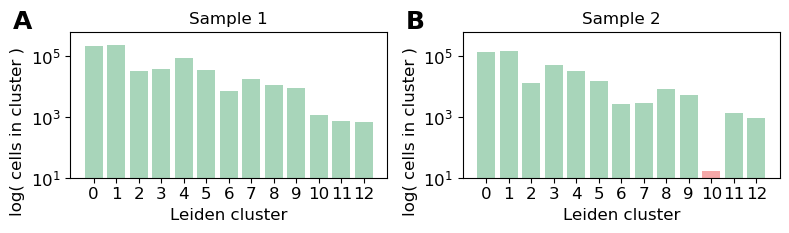

In [8]:

celltype_cols = [col for col in pivot_df_s1.columns if col != "leiden_cluster"]

# Compute total cells per cluster
df_s1_counts = pivot_df_s1.copy()
df_s1_counts["total_cells"] = df_s1_counts[celltype_cols].sum(axis=1)
df_s2_counts = pivot_df_s2.copy()
df_s2_counts["total_cells"] = df_s2_counts[celltype_cols].sum(axis=1)

# Sort by cluster ID
df_s1_counts = df_s1_counts.sort_values("leiden_cluster")
df_s2_counts = df_s2_counts.sort_values("leiden_cluster")
clusters = df_s1_counts.index

# Define colors: pastel green for all, pastel red for cluster 10
colors_s1 = ["#A8D5BA" for c in clusters]
colors_s2 = ["#A8D5BA" if c != 10 else "#F5A8A8" for c in clusters]




# Plot
fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(8, 2.5))
axs[0].bar(clusters, df_s1_counts["total_cells"], color=colors_s1)

label_size = 12
tick_size = 12

axs[0].set_yscale("log")
axs[0].set_xlabel("Leiden cluster", fontsize=label_size)
axs[0].set_ylabel("log( cells in cluster )          ", fontsize=label_size)
axs[0].set_xticks(clusters)
axs[0].tick_params(axis="x", labelsize=tick_size)
axs[0].tick_params(axis="y", labelsize=tick_size)
axs[0].set_title("Sample 1")
axs[0].set_ylim(10, 600000)

axs[1].bar(clusters, df_s2_counts["total_cells"], color=colors_s2)

axs[1].set_yscale("log")
axs[1].set_xlabel("Leiden cluster", fontsize=label_size)
axs[1].set_ylabel("log( cells in cluster )          ", fontsize=label_size)
axs[1].set_xticks(clusters)
axs[1].set_ylim(10, 600000)

axs[1].tick_params(axis="x", labelsize=tick_size)
axs[1].tick_params(axis="y", labelsize=tick_size)
axs[1].set_title("Sample 2")


for ax, label in zip(axs, ["A", "B"]):
    ax.text(
        x = -0.12,             # fractional x-position, just outside the left
        y = 1.15,             # fractional y-position, just above the top
        s = label,            # the text to draw
        transform = ax.transAxes,
        fontsize = 18,
        fontweight = "bold",
        va = "top",
        ha = "right",
    )

plt.tight_layout()
plt.show()



In [9]:
pivot_df_s2 = pivot_df_s2.drop(index=10)
pivot_df_s2

,Adipocytes,B_cells,Breast_cancer,Breast_glandular_cells,Breast_myoepithelial_cells,Dendritic_cells,Endothelial_cells,Epithelial_cells,Fibroblasts,Immune_cells,Macrophages,Mast_cells,Monocytes,NK_cells,Smooth_muscle_cells,T_cells,Unknown
leiden_cluster,,,,,,,,,,,,,,,,,
0,143.0,129.0,98589.0,3580.0,465.0,285.0,3159.0,1131.0,4695.0,11488.0,585.0,1822.0,2937.0,179.0,567.0,100.0,2.0
1,165.0,286.0,98198.0,3669.0,645.0,481.0,3653.0,1847.0,5911.0,15823.0,640.0,1596.0,3157.0,305.0,628.0,401.0,5.0
2,116.0,132.0,809.0,98.0,241.0,57.0,1558.0,140.0,5512.0,2630.0,153.0,313.0,592.0,36.0,295.0,55.0,4.0
3,142.0,298.0,18414.0,1546.0,563.0,331.0,3213.0,1243.0,9422.0,9643.0,526.0,1234.0,2120.0,294.0,922.0,236.0,7.0
4,61.0,93.0,18862.0,685.0,386.0,102.0,1266.0,365.0,2867.0,3911.0,216.0,548.0,850.0,78.0,427.0,43.0,0.0
5,211.0,83.0,4660.0,298.0,114.0,72.0,1466.0,285.0,3282.0,2821.0,123.0,283.0,534.0,56.0,502.0,59.0,9.0
6,185.0,13.0,959.0,41.0,10.0,15.0,309.0,57.0,408.0,316.0,28.0,53.0,83.0,5.0,93.0,4.0,2.0
7,144.0,13.0,830.0,62.0,15.0,7.0,385.0,73.0,542.0,413.0,17.0,58.0,105.0,5.0,119.0,8.0,1.0
8,6.0,10.0,6094.0,191.0,25.0,19.0,203.0,88.0,357.0,691.0,37.0,125.0,151.0,8.0,34.0,5.0,0.0


## Barplot

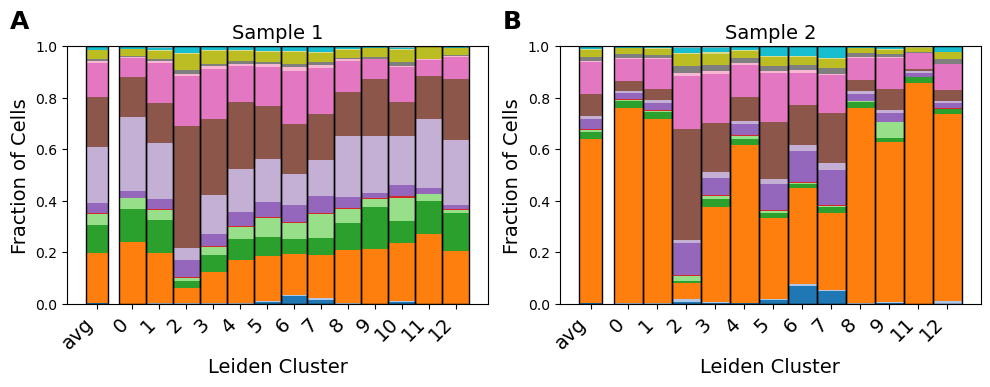

In [10]:
import matplotlib.patches as patches

# ─── 0) Your colour‐map DataFrame, unchanged ───────────────────────────────────
celltypes = [ct for ct in pivot_df_s2.columns if ct not in ["leiden_cluster", "Unknown"]]
n_types   = len(celltypes)
cmap      = plt.get_cmap("tab20")
positions = np.linspace(0, 1, n_types, endpoint=True)
hex_colors = [matplotlib.colors.to_hex(cmap(pos)) for pos in positions]
color_df   = pd.DataFrame({"celltype": celltypes, "hex_color": hex_colors})

# ─── I) Global font settings ──────────────────────────────────────────────────
title_fontsize     = 14
label_fontsize     = 14
tick_fontsize      = 14
panel_fontsize     = 18

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Liberation Sans", "Bitstream Vera Sans"]
})

def plot_celltype_fractions_with_global(pivot_df, color_df, ax, title):
    # bar‐widths
    avg_width     = 0.8
    cluster_width = 1.0

    # build colour map
    color_map = dict(zip(color_df["celltype"], color_df["hex_color"]))

    # 1) per‐cluster fractions
    fractions = pivot_df.div(pivot_df.sum(axis=1), axis=0)
    fractions = fractions.loc[fractions.sum(axis=1) > 0]

    # 2) sort clusters by integer prefix
    def sort_key(lbl):
        return int(str(lbl).split("-", 1)[0])
    clusters = sorted(fractions.index, key=sort_key)

    # 3) global fractions
    global_counts = pivot_df.sum(axis=0)
    global_fracs  = global_counts / global_counts.sum()

    # 4) x positions
    avg_x = 0.0
    # start clusters immediately after the avg bar + half a cluster bar
    cluster_x = avg_width + cluster_width/2 + np.arange(len(clusters)) * cluster_width

    # 5) plot segments
    bottom_glob     = 0.0
    bottom_clusters = np.zeros(len(clusters))
    for ct in fractions.columns:
        # avg segment
        ax.bar(
            avg_x, 
            global_fracs[ct], 
            bottom=bottom_glob, 
            width=avg_width,
            color=color_map.get(ct, "#333333"),
        )
        bottom_glob += global_fracs[ct]

        # per‐cluster segments
        vals = fractions.loc[clusters, ct].values
        ax.bar(
            cluster_x, 
            vals, 
            bottom=bottom_clusters, 
            width=cluster_width,
            color=color_map.get(ct, "#333333"),
            label=ct
        )
        bottom_clusters += vals

    # 6) outline each full bar
    all_x     = np.concatenate(([avg_x], cluster_x))
    all_width = [avg_width] + [cluster_width]*len(clusters)
    for x, w in zip(all_x, all_width):
        rect = patches.Rectangle(
            (x - w/2, 0),  # lower‐left corner
            w,             # width
            1.0,           # total height
            fill=False,
            edgecolor="black",
            linewidth=1
        )
        ax.add_patch(rect)

    # 7) ticks & labels with our font sizes
    labels = ["avg"] + clusters
    ax.set_xticks(all_x)
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=tick_fontsize)

    ax.set_xlabel("Leiden Cluster", fontsize=label_fontsize)
    ax.set_ylabel("Fraction of Cells", fontsize=label_fontsize)
    ax.set_title(title, fontsize=title_fontsize)

# ─── II) draw the figure with panels A) / B) ────────────────────────────────────
fig, axs = plt.subplots(ncols=2, figsize=(10, 4))

plot_celltype_fractions_with_global(pivot_df_s1[celltypes], color_df, axs[0], "Sample 1")
plot_celltype_fractions_with_global(pivot_df_s2[celltypes], color_df, axs[1], "Sample 2")

# add panel letters
for ax, letter in zip(axs, ["A", "B"]):
    ax.text(
        -0.09, 1.05, f"{letter}",
        transform=ax.transAxes,
        fontsize=panel_fontsize,
        fontweight="bold",
        va="bottom",
        ha="right"
    )

plt.tight_layout()
plt.show()


In [11]:
pivot_df_s1

,Adipocytes,B_cells,Breast_cancer,Breast_glandular_cells,Breast_myoepithelial_cells,Dendritic_cells,Endothelial_cells,Epithelial_cells,Fibroblasts,Immune_cells,Macrophages,Mast_cells,Monocytes,NK_cells,Smooth_muscle_cells,T_cells,Unknown
leiden_cluster,,,,,,,,,,,,,,,,,
0,116.0,265.0,50214.0,27129.0,8871.0,316.0,5715.0,60627.0,32732.0,15178.0,729.0,1239.0,5560.0,386.0,1612.0,222.0,5.0
1,281.0,868.0,41914.0,27861.0,8828.0,933.0,8183.0,47242.0,34554.0,34020.0,1606.0,1594.0,6929.0,779.0,1794.0,996.0,79.0
2,59.0,100.0,1868.0,792.0,433.0,61.0,2188.0,1478.0,15250.0,6242.0,229.0,507.0,1999.0,80.0,782.0,55.0,0.0
3,48.0,110.0,4506.0,2347.0,1168.0,127.0,1703.0,5618.0,10963.0,7269.0,365.0,352.0,1886.0,162.0,365.0,95.0,5.0
4,128.0,307.0,13887.0,6801.0,3837.0,228.0,4546.0,14189.0,21652.0,11750.0,564.0,966.0,3135.0,248.0,1121.0,172.0,1.0
5,288.0,159.0,5889.0,2411.0,2573.0,135.0,1995.0,5609.0,6894.0,5207.0,357.0,314.0,1288.0,115.0,499.0,90.0,74.0
6,224.0,23.0,1095.0,407.0,423.0,25.0,454.0,829.0,1366.0,1410.0,102.0,82.0,317.0,27.0,114.0,20.0,2.0
7,288.0,93.0,2815.0,1053.0,1602.0,59.0,1054.0,2368.0,2948.0,2953.0,223.0,167.0,612.0,51.0,322.0,48.0,5.0
8,19.0,30.0,2304.0,1140.0,629.0,31.0,469.0,2627.0,1931.0,1300.0,95.0,74.0,342.0,24.0,91.0,25.0,8.0


In [12]:
pivot_df_s2_merged = pivot_df_s2[celltypes].copy()

# 2) sum clusters 5,6,7 into a Series
#    (assumes your index labels ARE integers; if they are strings, use ['5','6','7'] instead)
merged_row = pivot_df_s2_merged.loc[[5, 6, 7]].sum(axis=0)

# 3) drop the old 5,6,7 rows
pivot_df_s2_merged = pivot_df_s2_merged.drop(index=[5, 6, 7])

# 4) insert the new merged row under a fresh label "5-7"
pivot_df_s2_merged.loc["5-7"] = merged_row

# 5) (Optional) reorder so "5-7" sits where you expect:
#    For instance, if you want numeric sort except that "5-7" goes between 4 and 8:
new_index = sorted(
    pivot_df_s2_merged.index,
    key=lambda lbl: int(str(lbl).split("-")[0])
)
pivot_df_s2_merged = pivot_df_s2_merged.loc[new_index]

# Now inspect:
pivot_df_s2_merged

,Adipocytes,B_cells,Breast_cancer,Breast_glandular_cells,Breast_myoepithelial_cells,Dendritic_cells,Endothelial_cells,Epithelial_cells,Fibroblasts,Immune_cells,Macrophages,Mast_cells,Monocytes,NK_cells,Smooth_muscle_cells,T_cells
leiden_cluster,,,,,,,,,,,,,,,,
0,143.0,129.0,98589.0,3580.0,465.0,285.0,3159.0,1131.0,4695.0,11488.0,585.0,1822.0,2937.0,179.0,567.0,100.0
1,165.0,286.0,98198.0,3669.0,645.0,481.0,3653.0,1847.0,5911.0,15823.0,640.0,1596.0,3157.0,305.0,628.0,401.0
2,116.0,132.0,809.0,98.0,241.0,57.0,1558.0,140.0,5512.0,2630.0,153.0,313.0,592.0,36.0,295.0,55.0
3,142.0,298.0,18414.0,1546.0,563.0,331.0,3213.0,1243.0,9422.0,9643.0,526.0,1234.0,2120.0,294.0,922.0,236.0
4,61.0,93.0,18862.0,685.0,386.0,102.0,1266.0,365.0,2867.0,3911.0,216.0,548.0,850.0,78.0,427.0,43.0
5-7,540.0,109.0,6449.0,401.0,139.0,94.0,2160.0,415.0,4232.0,3550.0,168.0,394.0,722.0,66.0,714.0,71.0
8,6.0,10.0,6094.0,191.0,25.0,19.0,203.0,88.0,357.0,691.0,37.0,125.0,151.0,8.0,34.0,5.0
9,18.0,13.0,3096.0,81.0,302.0,11.0,165.0,55.0,405.0,607.0,22.0,43.0,93.0,6.0,39.0,15.0
11,1.0,0.0,1154.0,33.0,0.0,0.0,18.0,14.0,10.0,81.0,0.0,9.0,18.0,4.0,5.0,0.0


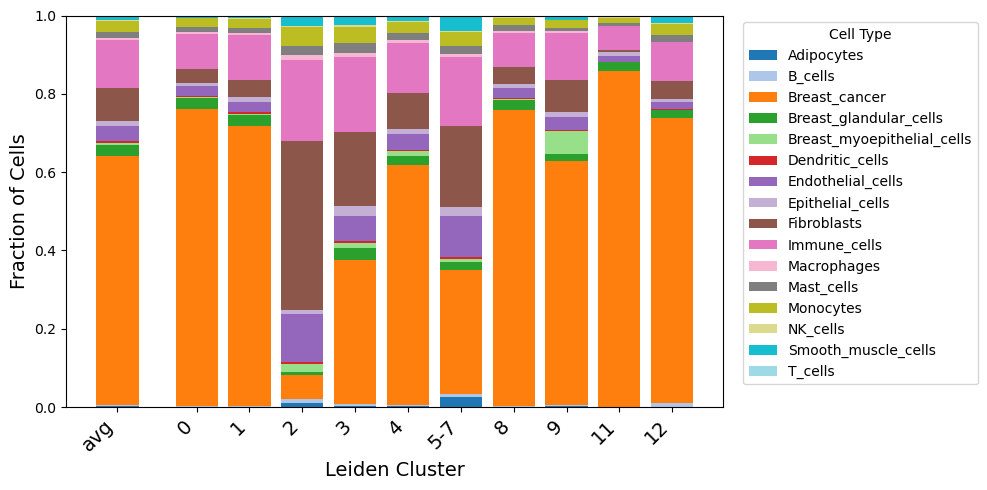

In [13]:


color_map = dict(zip(color_df["celltype"], color_df["hex_color"]))

# 1) Per‐cluster fractions
fractions = pivot_df_s2_merged.div(pivot_df_s2_merged.sum(axis=1), axis=0)
fractions = fractions.loc[fractions.sum(axis=1) > 0]

# 2) Sort clusters by the integer before any dash
def sort_key(lbl):
    s = str(lbl)
    # take the part before a dash, then int()
    return int(s.split("-", 1)[0])
clusters = sorted(fractions.index, key=sort_key)

# 3) Global (“avg”) fractions
global_counts = pivot_df_s2_merged.sum(axis=0)
global_fracs  = global_counts / global_counts.sum()

# 4) X positions: avg at 0, clusters start at 1.5
avg_x     = 0.0
cluster_x = np.arange(len(clusters)) + 1.5

# 5) Plot
fig, ax = plt.subplots(figsize=(10, 5))
bottom_glob     = 0.0
bottom_clusters = np.zeros(len(clusters))

for ct in fractions.columns:
    # global bar segment
    ax.bar(
        avg_x,
        global_fracs[ct],
        bottom=bottom_glob,
        width=0.8,
        color=color_map.get(ct, "#333333"),
    )
    bottom_glob += global_fracs[ct]

    # per‐cluster segments
    vals = fractions.loc[clusters, ct].values
    ax.bar(
        cluster_x,
        vals,
        bottom=bottom_clusters,
        width=0.8,
        color=color_map.get(ct, "#333333"),
        label=ct
    )
    bottom_clusters += vals

# 6) Ticks & labels
all_x      = np.concatenate(([avg_x], cluster_x))
all_labels = ["avg"] + clusters
ax.set_xticks(all_x)

label_size = 14
tick_size = 14

ax.set_xticklabels(all_labels, rotation=45, ha="right", fontsize=tick_size)


ax.set_xlabel("Leiden Cluster", fontsize=label_size)
ax.set_ylabel("Fraction of Cells", fontsize=label_size)
ax.legend(title="Cell Type", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

/tmp/ipykernel_528985/516844597.py:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(y_ticks, ha="right", fontsize=tick_size)


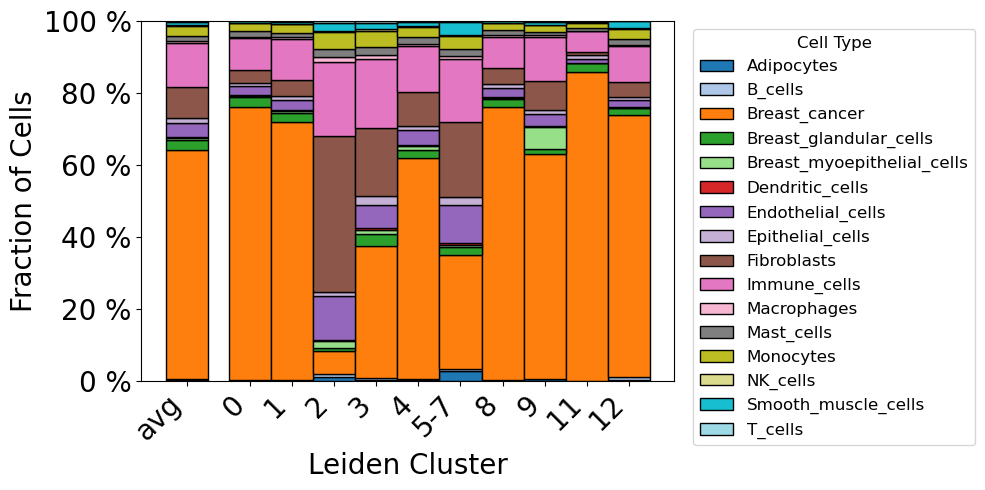

In [14]:
color_map = dict(zip(color_df["celltype"], color_df["hex_color"]))

# 2) Compute per‐cluster fractions and drop empty clusters
fractions = pivot_df_s2_merged.div(pivot_df_s2_merged.sum(axis=1), axis=0)
fractions = fractions.loc[fractions.sum(axis=1) > 0]

# 3) Robust numeric sort for labels like "5-7"
def sort_key(lbl):
    s = str(lbl)
    return int(s.split("-", 1)[0])

clusters = sorted(fractions.index, key=sort_key)

# 4) Compute global fractions ("avg" column)
global_counts = pivot_df_s2_merged.sum(axis=0)
global_fracs = global_counts / global_counts.sum()

# 5) X positions: avg at 0, clusters start at 1.5 (so we can adjust gap)
avg_x     = 0.0
cluster_x = np.arange(len(clusters)) + 1.5

# 6) Font sizes
label_size = 20
tick_size  = 20

# 7) Plot
fig, ax = plt.subplots(figsize=(10, 5))
bottom_glob     = 0.0
bottom_clusters = np.zeros(len(clusters))

for ct in fractions.columns:
    # Global ("avg") bar segment
    ax.bar(
        avg_x,
        global_fracs[ct],
        bottom=bottom_glob,
        width=1.0,                 # no gap within avg itself
        color=color_map.get(ct, "#333333"),
        edgecolor="black",         # black border
        linewidth=1
    )
    bottom_glob += global_fracs[ct]

    # Per‐cluster bar segments
    vals = fractions.loc[clusters, ct].values
    ax.bar(
        cluster_x,
        vals,
        bottom=bottom_clusters,
        width=1.0,                 # width=1.0 makes bars butt up against each other
        color=color_map.get(ct, "#333333"),
        edgecolor="black",         # black border
        linewidth=1,
        label=ct
    )
    bottom_clusters += vals

# 8) Ticks & labels
all_x      = np.concatenate(([avg_x], cluster_x))
all_labels = ["avg"] + clusters

ax.set_xticks(all_x)
ax.set_xticklabels(all_labels, rotation=45, ha="right", fontsize=tick_size)
ax.set_xlabel("Leiden Cluster", fontsize=label_size)
ax.set_ylabel("Fraction of Cells", fontsize=label_size)
y_ticks = [f"{i} %" for i in range(0, 120, 20)]
ax.set_yticklabels(y_ticks, ha="right", fontsize=tick_size)

ax.legend(title="Cell Type", fontsize=12, title_fontsize=12,
          bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

## Make spatial plots

In [30]:


sdata_sample2["morphology_filtered"] = sdata_sample2["morphology_filtered"][sdata_sample2["morphology_filtered"].obs["leiden"] != "10"].copy()

# 2. Recode clusters "5", "6", "7" into "5-7"
sdata_sample2["morphology_filtered"].obs["leiden"] = sdata_sample2["morphology_filtered"].obs["leiden"].replace({"5": "5-7", "6": "5-7", "7": "5-7"})

# 3. Clean up categories
sdata_sample2["morphology_filtered"].obs["leiden"] = sdata_sample2["morphology_filtered"].obs["leiden"].astype("category")
sdata_sample2["morphology_filtered"].obs["leiden"].cat.remove_unused_categories()
sdata_sample2["morphology_filtered"].obs["leiden"].value_counts()

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `morphology_filtered` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/tmp/ipykernel_528985/1124336663.py:4: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  sdata_sample2["morphology_filtered"].obs["leiden"] = sdata_sample2["morphology_filtered"].obs["leiden"].replace({"5": "5-7", "6": "5-7", "7": "5-7"})


leiden
2      1702
1      1678
0      1615
3      1377
5-7    1110
4       462
8        90
9        76
11       13
12       10
Name: count, dtype: int64

INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


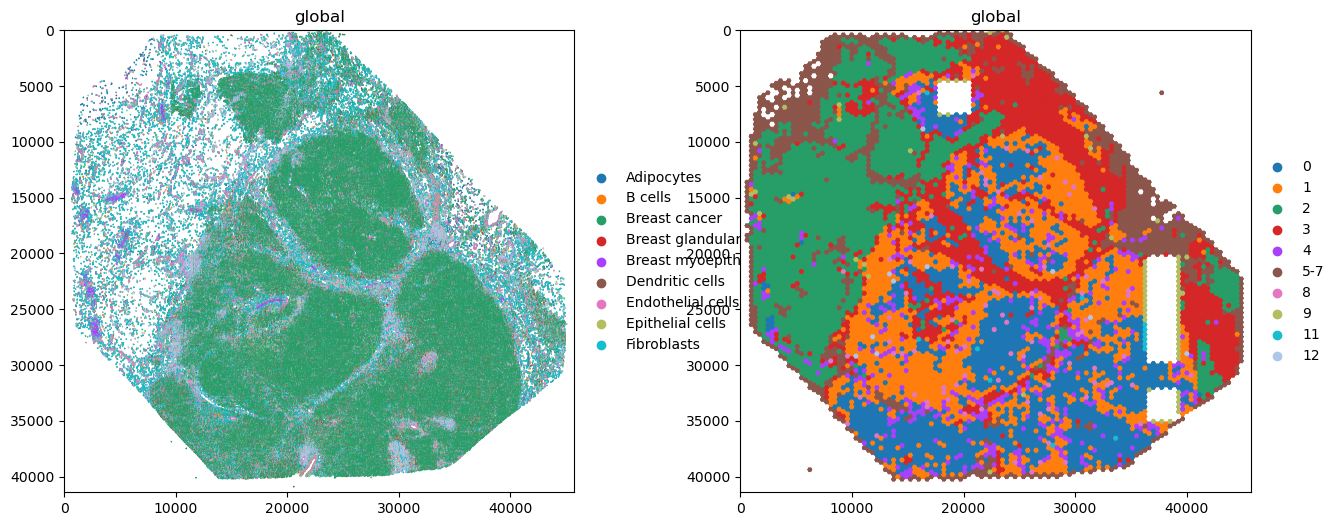

In [31]:
fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 6))

(
    sdata_sample2
    # .pl.render_images("hne_baked")
    .pl.render_labels(
        "cell_labels",
        color="predicted_celltype",
        table_name="table", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[0])
)

(
    sdata_sample2
    # .pl.render_images("hne_baked")
    .pl.render_labels(
        "filtered_hexes",
        color="leiden",
        table_name="morphology_filtered", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[1])
)

INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


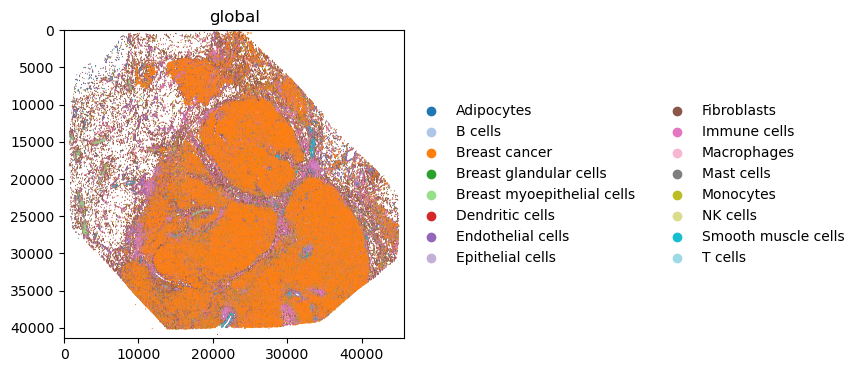

In [17]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6, 4))

(
    sdata_sample2
    # .pl.render_images("hne_baked")
    .pl.render_labels(
        "cell_labels",
        color="predicted_celltype",
        groups=[g.replace("_", " ") for g in list(color_map.keys())],
        palette=list(color_map.values()),
        table_name="table", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=ax)
)

In [18]:
color_map

{'Adipocytes': '#1f77b4',
 'B_cells': '#aec7e8',
 'Breast_cancer': '#ff7f0e',
 'Breast_glandular_cells': '#2ca02c',
 'Breast_myoepithelial_cells': '#98df8a',
 'Dendritic_cells': '#d62728',
 'Endothelial_cells': '#9467bd',
 'Epithelial_cells': '#c5b0d5',
 'Fibroblasts': '#8c564b',
 'Immune_cells': '#e377c2',
 'Macrophages': '#f7b6d2',
 'Mast_cells': '#7f7f7f',
 'Monocytes': '#bcbd22',
 'NK_cells': '#dbdb8d',
 'Smooth_muscle_cells': '#17becf',
 'T_cells': '#9edae5'}

## H&E images for supplementaries

### Call celltypes for both datasets

In [19]:
gene_groups_10x = pd.read_csv(data_dir / "Xenium_V1_FFPE_Human_Breast_Addon_Input_gene_groups.csv")
marker_dict = (
    gene_groups_10x.dropna(subset=["group"])
      .groupby("group")["gene"]
      .apply(list)
      .to_dict()
)

def add_predicted_celltype(
    adata,
    marker_dict,
    threshold: float = 0.0,
    use_raw: bool = False
):
    """Scores gene-sets and predict cell types in an AnnData object."""
    score_cols = []
    # Score each marker gene‐set
    for ct, genes in marker_dict.items():
        score_name = f"{ct}_score"
        sc.tl.score_genes(
            adata,
            gene_list=genes,
            score_name=score_name,
            use_raw=use_raw
        )
        score_cols.append(score_name)

    # Determine, for each cell, the max score and its cell‐type
    scores_df = adata.obs[score_cols]
    max_scores = scores_df.max(axis=1)
    best_ct = (
        scores_df
        .idxmax(axis=1)
        .str.replace("_score", "", regex=False)
    )

    # Assign prediction (or "Unknown")
    adata.obs["predicted_celltype"] = np.where(
        max_scores > threshold,
        best_ct,
        "Unknown"
    )

    adata.obs.columns = [col.replace(" ", "_") if isinstance(col, str) else col for col in adata.obs.columns]
    adata.obs["predicted_celltype"] = pd.Categorical(adata.obs["predicted_celltype"])

    return adata

add_predicted_celltype(sdata_sample1["table"], marker_dict, threshold=0.1, use_raw=False)
sdata_sample1["table"].obs["predicted_celltype"].value_counts()

predicted_celltype
Epithelial cells              192673
Fibroblasts                   115212
Breast cancer                  74785
Immune cells                   62027
Breast glandular cells         46719
Breast myoepithelial cells     22195
Endothelial cells              20647
Monocytes                      12855
Smooth muscle cells             7994
Macrophages                     5206
Mast cells                      3447
Unknown                         2225
NK cells                        2067
B cells                         1884
T cells                         1746
Dendritic cells                 1494
Adipocytes                      1350
Name: count, dtype: int64

In [20]:
add_predicted_celltype(sdata_sample2["table"], marker_dict, threshold=0.1, use_raw=False)
sdata_sample2["table"].obs["predicted_celltype"].value_counts()

predicted_celltype
Breast cancer                 212039
Epithelial cells               52386
Immune cells                   30083
Fibroblasts                    28240
Endothelial cells              12389
Monocytes                       7651
Smooth muscle cells             4249
Breast glandular cells          4132
Mast cells                      3549
Macrophages                     2567
Breast myoepithelial cells      2049
Unknown                         1368
Dendritic cells                 1168
NK cells                        1009
B cells                          971
T cells                          934
Adipocytes                       820
Name: count, dtype: int64

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


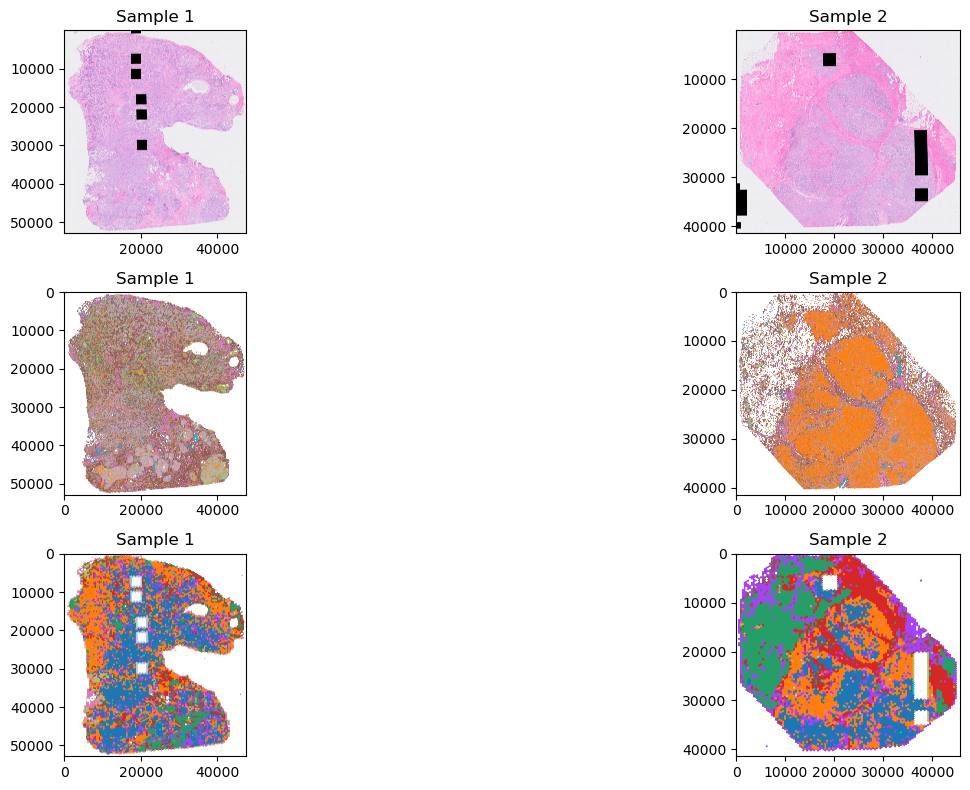

In [21]:
fig, axs = plt.subplots(ncols=2, nrows=3, figsize=(18, 8))

axs = axs.ravel()

# tissue 1
(
    sdata_sample1
    .pl.render_images("hne_baked")
    .pl.show(ax=axs[0], title="Sample 1")
)

# celltypes 1
(
    sdata_sample1
    .pl.render_labels(
        "cell_labels",
        color="predicted_celltype",
        groups=[g.replace("_", " ") for g in list(color_map.keys())],
        palette=list(color_map.values()),
        table_name="table", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[2], title="Sample 1")
)

# hexes 1
(
    sdata_sample1
    .pl.render_labels(
        "filtered_hexes",
        color="leiden",
        table_name="morphology_filtered", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[4], title="Sample 1")
)

# tissue 2
(
    sdata_sample2
    .pl.render_images("hne_baked")
    .pl.show(ax=axs[1], title="Sample 2")
)

# celltypes 2
(
    sdata_sample2
    .pl.render_labels(
        "cell_labels",
        color="predicted_celltype",
        groups=[g.replace("_", " ") for g in list(color_map.keys())],
        palette=list(color_map.values()),
        table_name="table", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[3], title="Sample 2")
)

# hexes 2
(
    sdata_sample2
    .pl.render_labels(
        "filtered_hexes",
        color="leiden",
        table_name="morphology_filtered", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=axs[5], title="Sample 2")
)

# remove any legends that were created
for ax in axs:
    leg = ax.get_legend()
    if leg:
        leg.remove()

plt.tight_layout()

## Tumour hotness plot

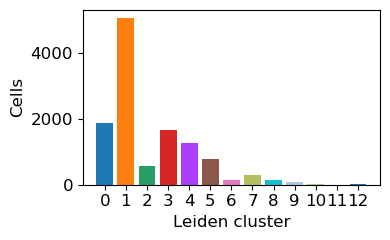

In [27]:
immune_hot_celltypes = [
    "B_cells",
    "Dendritic_cells",
    # "Macrophages",
    "NK_cells",
    "T_cells"
]

leiden_colors = sdata_sample2["morphology_filtered"].uns["leiden_colors"]
leiden_clusters = list(range(len(leiden_colors)+1))

immune_hot_s1 = pivot_df_s1[immune_hot_celltypes].sum(axis=1)
immune_hot_s2 = pivot_df_s2[immune_hot_celltypes].sum(axis=1)
immune_hot_df = pd.concat([immune_hot_s1, immune_hot_s2], axis=1).sum(axis=1)

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(4, 2.5))
ax.bar(leiden_clusters, immune_hot_df, color=leiden_colors)

label_size = 12
tick_size = 12

# ax.set_yscale("log")
ax.set_xlabel("Leiden cluster", fontsize=label_size)
ax.set_ylabel("Cells", fontsize=label_size)
ax.set_xticks(leiden_clusters)
ax.tick_params(axis="x", labelsize=tick_size)
ax.tick_params(axis="y", labelsize=tick_size)
# ax.set_title("Sample 1")
#ax.set_ylim(10, 600000)

plt.tight_layout()
plt.show()


INFO     Rasterizing image for faster rendering.                                                                   


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:777: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


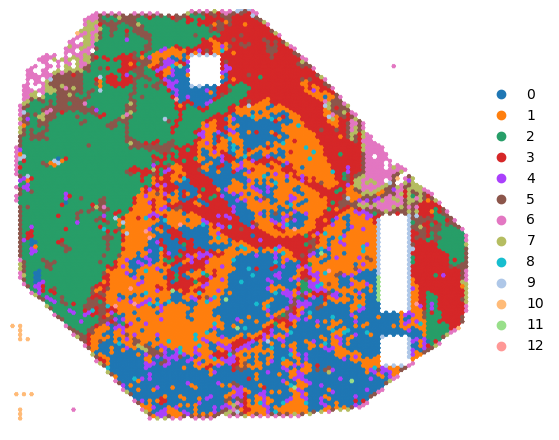

In [33]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6, 6))

(
    sdata_sample2
    .pl.render_labels(
        "filtered_hexes",
        color="leiden",
        table_name="morphology_filtered", 
        fill_alpha=1, 
        outline_alpha=1
    )
    .pl.show(ax=ax, title="")
)
ax.grid(False)

# turn off ticks and tick labels
ax.set_xticks([])
ax.set_yticks([])

# turn off the entire axis (frame, ticks, labels, spines)
ax.set_axis_off()